In [1]:
%matplotlib inline
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Can we use historical financial and operational data of Indian paint companies to predict their future financial performance, particularly next-period/year revenue?

In [2]:
import pandas as pd
annual_features = pd.read_csv(('data/processed/' if Path('data/processed').exists() else '../data/processed/') + 'annual_features.csv', sep=',', na_values=[''], quotechar='"')
annual_features

,company,basis,financial_year,period_end,ebit,gross_margin,ebitda_margin,ebit_margin,net_margin,revenue_growth,...,gross_margin_change,ebitda_margin_change,net_margin_change,net_debt,free_cash_flow,debt_to_equity,net_debt_to_ebitda,equity_to_assets,return_on_equity,return_on_assets
0,Asian Paints,Standalone,FY2015,2015-03-31,1787.41,44.7168,17.2594,15.3441,11.3951,NaN,...,NaN,NaN,NaN,NaN,851.41,NaN,NaN,58.1623,31.3787,18.2506
1,Asian Paints,Standalone,FY2016,2016-03-31,2241.20,48.3660,19.6077,17.7228,12.6320,8.5592,...,3.6493,2.3482,1.2369,-131.51,1292.16,0.0049,-0.0530,67.9170,26.9576,18.3088
2,Asian Paints,Standalone,FY2017,2017-03-31,2376.01,45.6919,21.1229,18.7870,14.2570,0.0097,...,-2.6741,1.5153,1.6250,-168.06,NaN,0.0054,-0.0629,68.0531,25.9402,17.6531
3,Asian Paints,Standalone,FY2018,2018-03-31,2609.39,43.5564,20.6136,18.4177,13.3739,12.0245,...,-2.1355,-0.5094,-0.8831,-110.97,NaN,0.0013,-0.0380,67.2955,24.2980,16.3515
4,Asian Paints,Standalone,FY2019,2019-03-31,2925.77,42.5894,20.1805,17.8490,13.0234,15.6969,...,-0.9670,-0.4330,-0.3506,-152.28,1327.99,0.0017,-0.0460,67.5738,24.0196,16.2310
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
80,Indigo Paints,Standalone,FY2026,2026-03-31,191.29,46.8875,18.5487,14.3814,10.9306,4.1443,...,0.3721,0.4175,-0.3395,-28.55,78.51,0.0000,-0.1157,75.3123,12.2967,9.2609
81,Indigo Paints,Consolidated,FY2023,2023-03-31,147.18,44.5418,16.9128,13.7125,12.2926,NaN,...,NaN,NaN,NaN,NaN,-83.15,NaN,NaN,73.1095,16.9997,12.4284
82,Indigo Paints,Consolidated,FY2024,2024-03-31,186.49,47.6345,18.2277,14.2785,11.3951,21.6858,...,3.0928,1.3149,-0.8975,-29.85,46.65,0.0034,-0.1254,71.0106,16.4974,11.7149
83,Indigo Paints,Consolidated,FY2025,2025-03-31,174.95,46.0218,17.4152,13.0494,10.6037,2.6476,...,-1.6128,-0.8125,-0.7914,-30.71,69.46,0.0062,-0.1315,73.0815,13.7942,10.0810


In [3]:
import pandas as pd
quarterly_reported = pd.read_csv(('data/processed/' if Path('data/processed').exists() else '../data/processed/') + 'quarterly_reported.csv', sep=',', na_values=[''], quotechar='"')
quarterly_reported

,company,basis,financial_year,quarter,period_end,revenue,raw_material_cost,ebitda,depreciation,exceptional_items,pat,eps_basic,accounting_standard,comparability_flags
0,Asian Paints,Standalone,FY2015,Q1,2014-06-30,2740.73,1556.23,489.56,54.70,-25.16,308.84,3.22,Indian GAAP,NaN
1,Asian Paints,Standalone,FY2015,Q2,2014-09-30,2995.71,1653.93,481.07,56.38,0.00,325.67,3.39,Indian GAAP,NaN
2,Asian Paints,Standalone,FY2015,Q3,2014-12-31,3025.41,1669.67,540.42,56.52,0.00,353.07,3.68,Indian GAAP,NaN
3,Asian Paints,Standalone,FY2015,Q4,2015-03-31,2886.97,1560.02,500.73,55.51,11.63,339.82,3.54,Indian GAAP,NaN
4,Asian Paints,Standalone,FY2016,Q1,2015-06-30,2938.16,1541.13,605.88,57.59,0.00,427.81,4.46,Indian GAAP,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307,Indigo Paints,Consolidated,FY2025,Q4,2025-03-31,387.56,206.08,87.42,13.23,NaN,57.40,11.94,Ind AS,NaN
308,Indigo Paints,Consolidated,FY2026,Q1,2025-06-30,308.86,167.11,44.31,14.82,NaN,26.06,5.44,Ind AS,NaN
309,Indigo Paints,Consolidated,FY2026,Q2,2025-09-30,312.06,172.33,46.54,15.06,NaN,25.25,5.27,Ind AS,NaN
310,Indigo Paints,Consolidated,FY2026,Q3,2025-12-31,358.78,191.03,68.35,15.03,-6.13,37.14,7.63,Ind AS,NaN


In [4]:
import pandas as pd
quarterly_features = pd.read_csv(('data/processed/' if Path('data/processed').exists() else '../data/processed/') + 'quarterly_features.csv', sep=',', na_values=[''], quotechar='"')
quarterly_features

,company,basis,financial_year,quarter,period_end,ebit,gross_margin,ebitda_margin,ebit_margin,net_margin,revenue_growth,ebitda_growth,pat_growth,gross_margin_change,ebitda_margin_change,net_margin_change
0,Asian Paints,Standalone,FY2015,Q1,2014-06-30,434.86,43.2184,17.8624,15.8666,11.2685,NaN,NaN,NaN,NaN,NaN,NaN
1,Asian Paints,Standalone,FY2015,Q2,2014-09-30,424.69,44.7900,16.0586,14.1766,10.8712,NaN,NaN,NaN,NaN,NaN,NaN
2,Asian Paints,Standalone,FY2015,Q3,2014-12-31,483.90,44.8118,17.8627,15.9945,11.6702,NaN,NaN,NaN,NaN,NaN,NaN
3,Asian Paints,Standalone,FY2015,Q4,2015-03-31,445.22,45.9634,17.3445,15.4217,11.7708,NaN,NaN,NaN,NaN,NaN,NaN
4,Asian Paints,Standalone,FY2016,Q1,2015-06-30,548.29,47.5478,20.6211,18.6610,14.5605,7.2036,23.7601,38.5216,4.3294,2.7587,3.2919
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307,Indigo Paints,Consolidated,FY2025,Q4,2025-03-31,74.19,46.8263,22.5565,19.1428,14.8106,0.6963,3.3455,5.4372,-2.0357,0.5782,0.6659
308,Indigo Paints,Consolidated,FY2026,Q1,2025-06-30,29.49,45.8946,14.3463,9.5480,8.4375,-0.6753,-6.4598,-2.2139,-0.7031,-0.8872,-0.1328
309,Indigo Paints,Consolidated,FY2026,Q2,2025-09-30,31.48,44.7766,14.9138,10.0878,8.0914,4.1832,12.1176,13.4322,1.0782,1.0554,0.6597
310,Indigo Paints,Consolidated,FY2026,Q3,2025-12-31,53.32,46.7557,19.0507,14.8615,10.3517,4.7166,19.5139,3.5983,0.1355,2.3587,-0.1117


In [5]:
import pandas as pd
annual_reported = pd.read_csv(('data/processed/' if Path('data/processed').exists() else '../data/processed/') + 'annual_reported.csv', sep=',', na_values=[''], quotechar='"')
annual_reported

,company,basis,financial_year,period_end,revenue,raw_material_cost,ebitda,depreciation,exceptional_items,pat,eps_basic,total_assets,net_worth,total_debt,cash,operating_cash_flow,capex,accounting_standard,comparability_flags
0,Asian Paints,Standalone,FY2015,2015-03-31,11648.83,6439.85,2010.52,223.11,-13.53,1327.40,13.84,7273.20,4230.26,NaN,NaN,1187.69,336.28,Indian GAAP,NaN
1,Asian Paints,Standalone,FY2016,2016-03-31,12645.88,6529.57,2479.56,238.36,-65.35,1597.43,16.65,8724.95,5925.72,29.27,160.78,1978.88,686.72,Indian GAAP,NaN
2,Asian Paints,Standalone,FY2017,2017-03-31,12647.11,6868.40,2671.44,295.43,0.00,1803.10,18.80,10214.06,6950.98,37.21,205.27,NaN,611.48,Ind AS,IND_AS_TRANSITION;PRE_GST_EXCISE
3,Asian Paints,Standalone,FY2018,2018-03-31,14167.86,7996.85,2920.50,311.11,NaN,1894.80,19.75,11587.93,7798.16,9.87,120.84,NaN,1358.32,Ind AS,PRE_GST_EXCISE
4,Asian Paints,Standalone,FY2019,2019-03-31,16391.78,9410.62,3307.95,382.18,NaN,2134.76,22.26,13152.37,8887.56,15.24,167.52,2395.25,1067.26,Ind AS,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
80,Indigo Paints,Standalone,FY2026,2026-03-31,1330.12,706.46,246.72,55.43,-5.85,145.39,30.51,1569.93,1182.35,0.00,28.55,211.37,132.86,Ind AS,NaN
81,Indigo Paints,Consolidated,FY2023,2023-03-31,1073.33,595.25,181.53,34.35,0.00,131.94,27.73,1061.60,776.13,NaN,48.79,116.11,199.26,Ind AS,NaN
82,Indigo Paints,Consolidated,FY2024,2024-03-31,1306.09,683.94,238.07,51.58,0.00,148.83,30.95,1270.43,902.14,3.08,32.93,151.01,104.36,Ind AS,NaN
83,Indigo Paints,Consolidated,FY2025,2025-03-31,1340.67,723.67,233.48,58.53,0.00,142.16,29.76,1410.18,1030.58,6.41,37.12,205.66,136.20,Ind AS,NaN


In [6]:
annual_reported.columns
annual_reported.info()
annual_reported.isnull().sum()



<class 'pandas.DataFrame'>
RangeIndex: 85 entries, 0 to 84
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   company              85 non-null     str    
 1   basis                85 non-null     str    
 2   financial_year       85 non-null     str    
 3   period_end           85 non-null     str    
 4   revenue              84 non-null     float64
 5   raw_material_cost    84 non-null     float64
 6   ebitda               83 non-null     float64
 7   depreciation         84 non-null     float64
 8   exceptional_items    64 non-null     float64
 9   pat                  85 non-null     float64
 10  eps_basic            83 non-null     float64
 11  total_assets         83 non-null     float64
 12  net_worth            81 non-null     float64
 13  total_debt           79 non-null     float64
 14  cash                 79 non-null     float64
 15  operating_cash_flow  77 non-null     float64
 16  cap

company                 0
basis                   0
financial_year          0
period_end              0
revenue                 1
raw_material_cost       1
ebitda                  2
depreciation            1
exceptional_items      21
pat                     0
eps_basic               2
total_assets            2
net_worth               4
total_debt              6
cash                    6
operating_cash_flow     8
capex                   7
accounting_standard     0
comparability_flags    58
dtype: int64

In [7]:
annual_features.columns

Index(['company', 'basis', 'financial_year', 'period_end', 'ebit',
       'gross_margin', 'ebitda_margin', 'ebit_margin', 'net_margin',
       'revenue_growth', 'ebitda_growth', 'pat_growth', 'gross_margin_change',
       'ebitda_margin_change', 'net_margin_change', 'net_debt',
       'free_cash_flow', 'debt_to_equity', 'net_debt_to_ebitda',
       'equity_to_assets', 'return_on_equity', 'return_on_assets'],
      dtype='str')

In [8]:
quarterly_features.columns

Index(['company', 'basis', 'financial_year', 'quarter', 'period_end', 'ebit',
       'gross_margin', 'ebitda_margin', 'ebit_margin', 'net_margin',
       'revenue_growth', 'ebitda_growth', 'pat_growth', 'gross_margin_change',
       'ebitda_margin_change', 'net_margin_change'],
      dtype='str')

In [9]:
quarterly_features.columns

Index(['company', 'basis', 'financial_year', 'quarter', 'period_end', 'ebit',
       'gross_margin', 'ebitda_margin', 'ebit_margin', 'net_margin',
       'revenue_growth', 'ebitda_growth', 'pat_growth', 'gross_margin_change',
       'ebitda_margin_change', 'net_margin_change'],
      dtype='str')

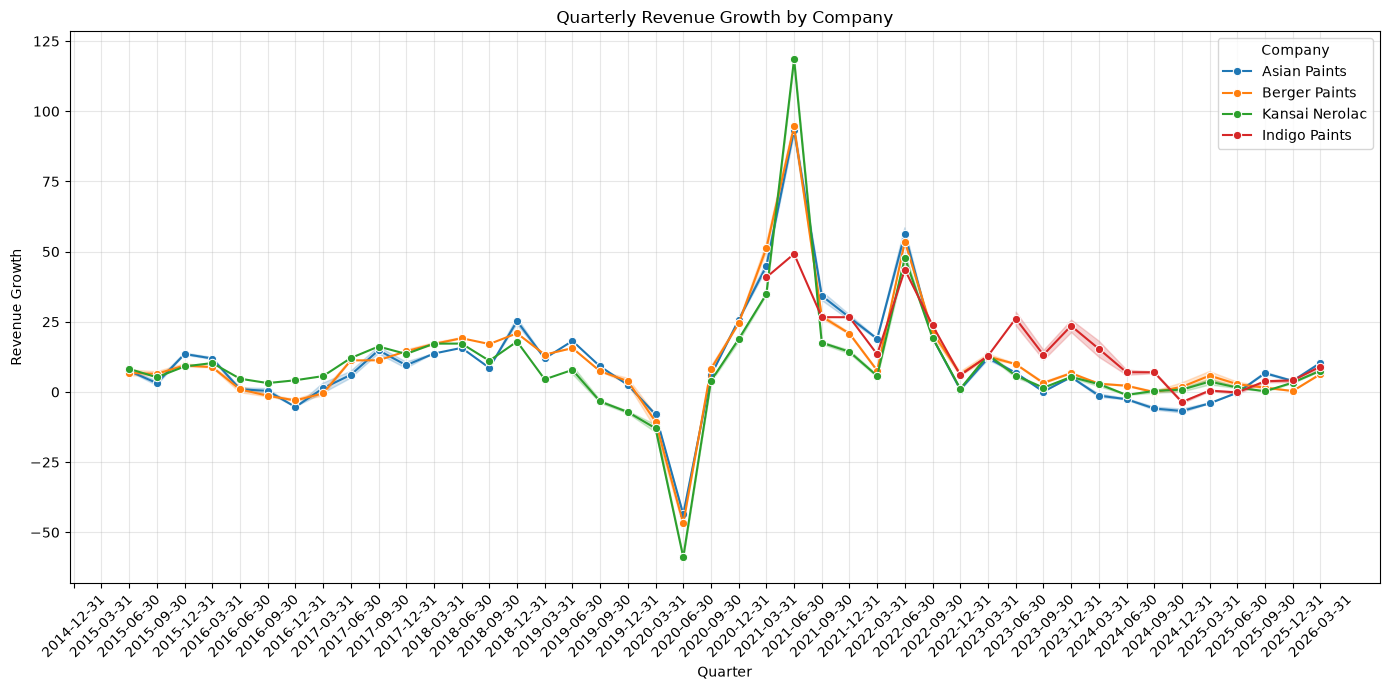

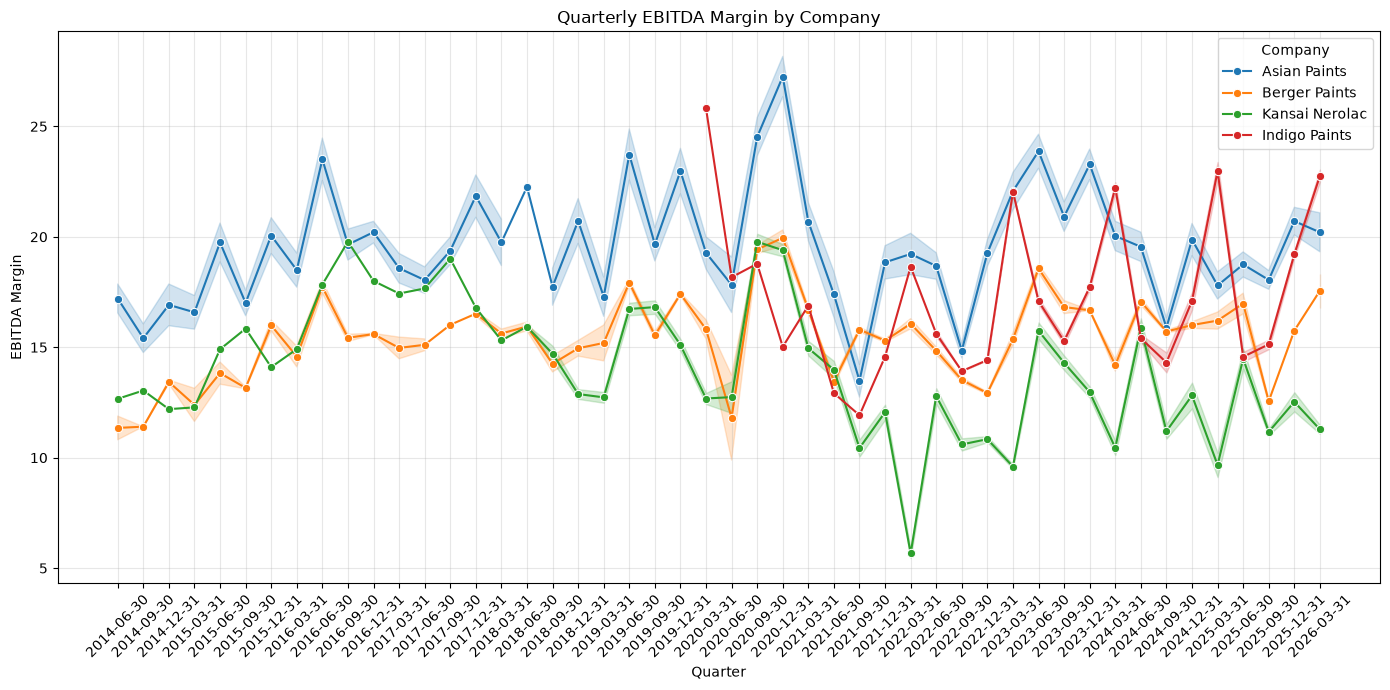

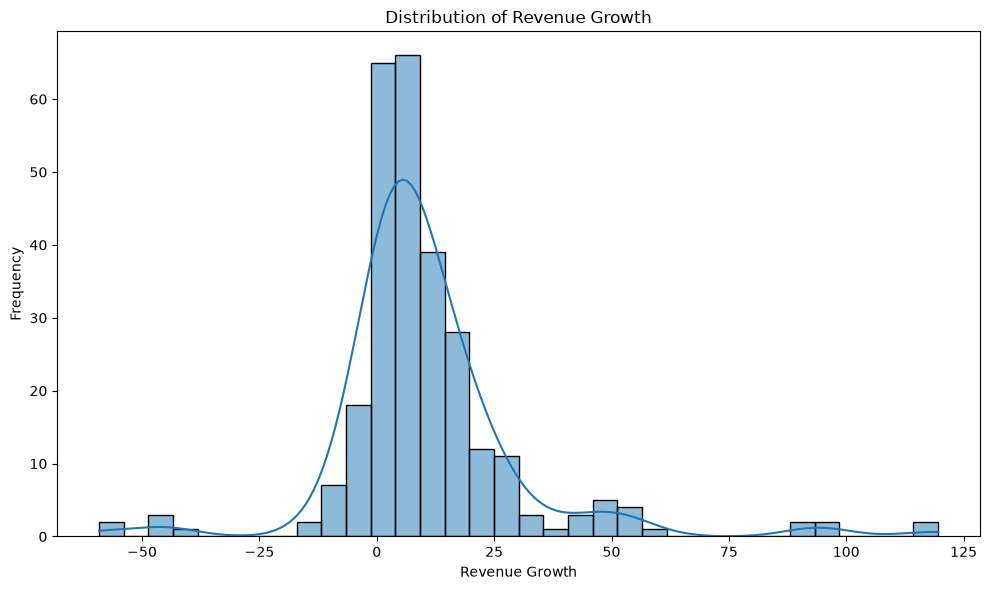

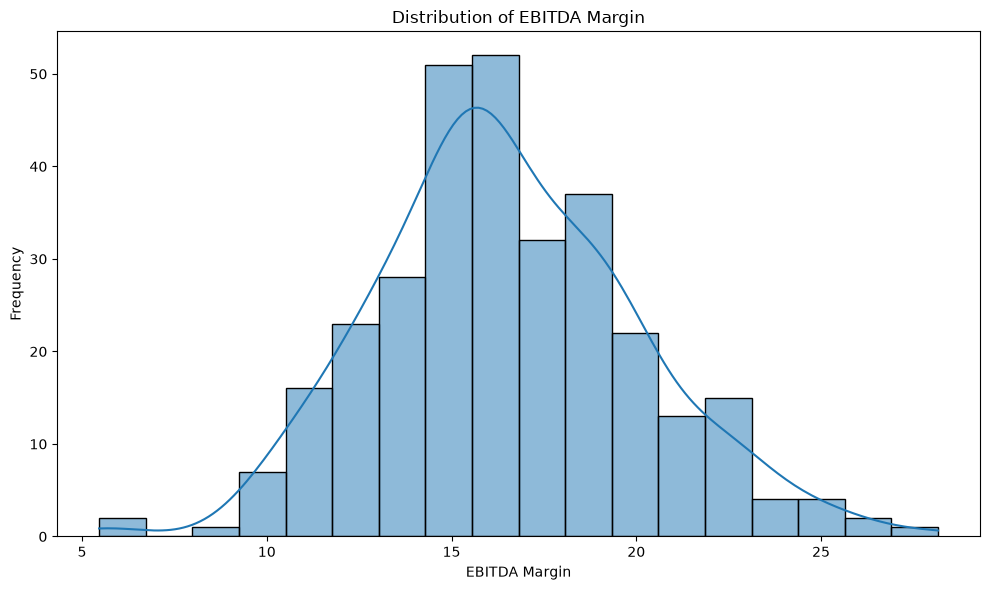

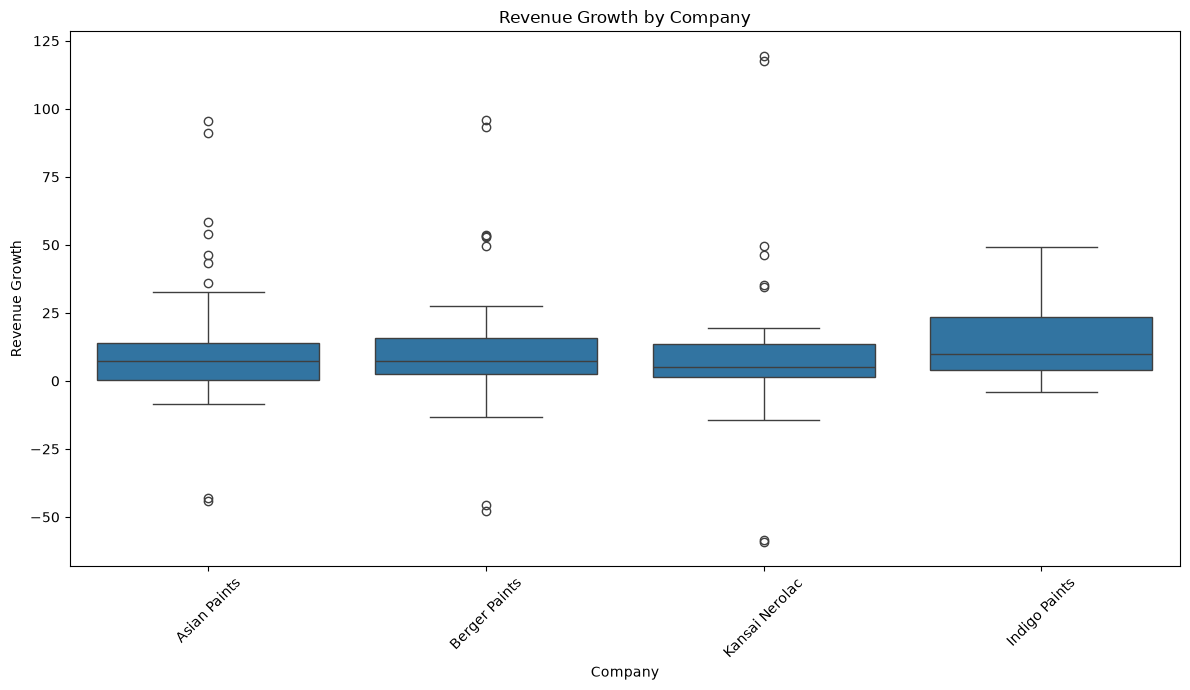

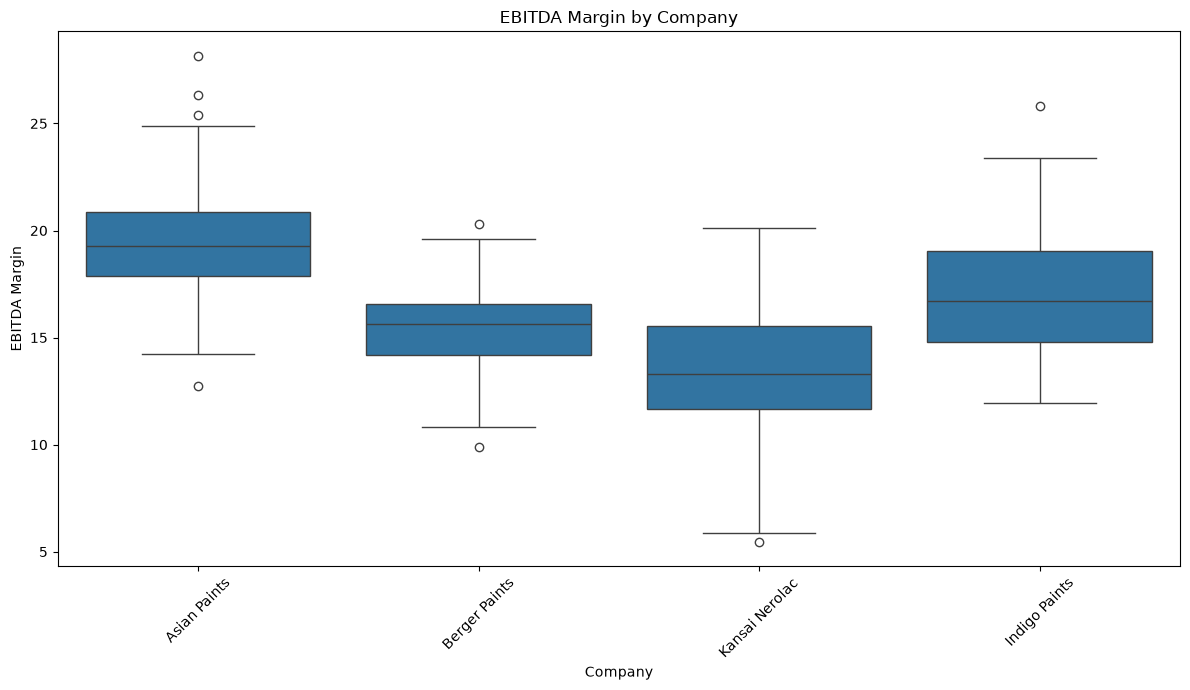

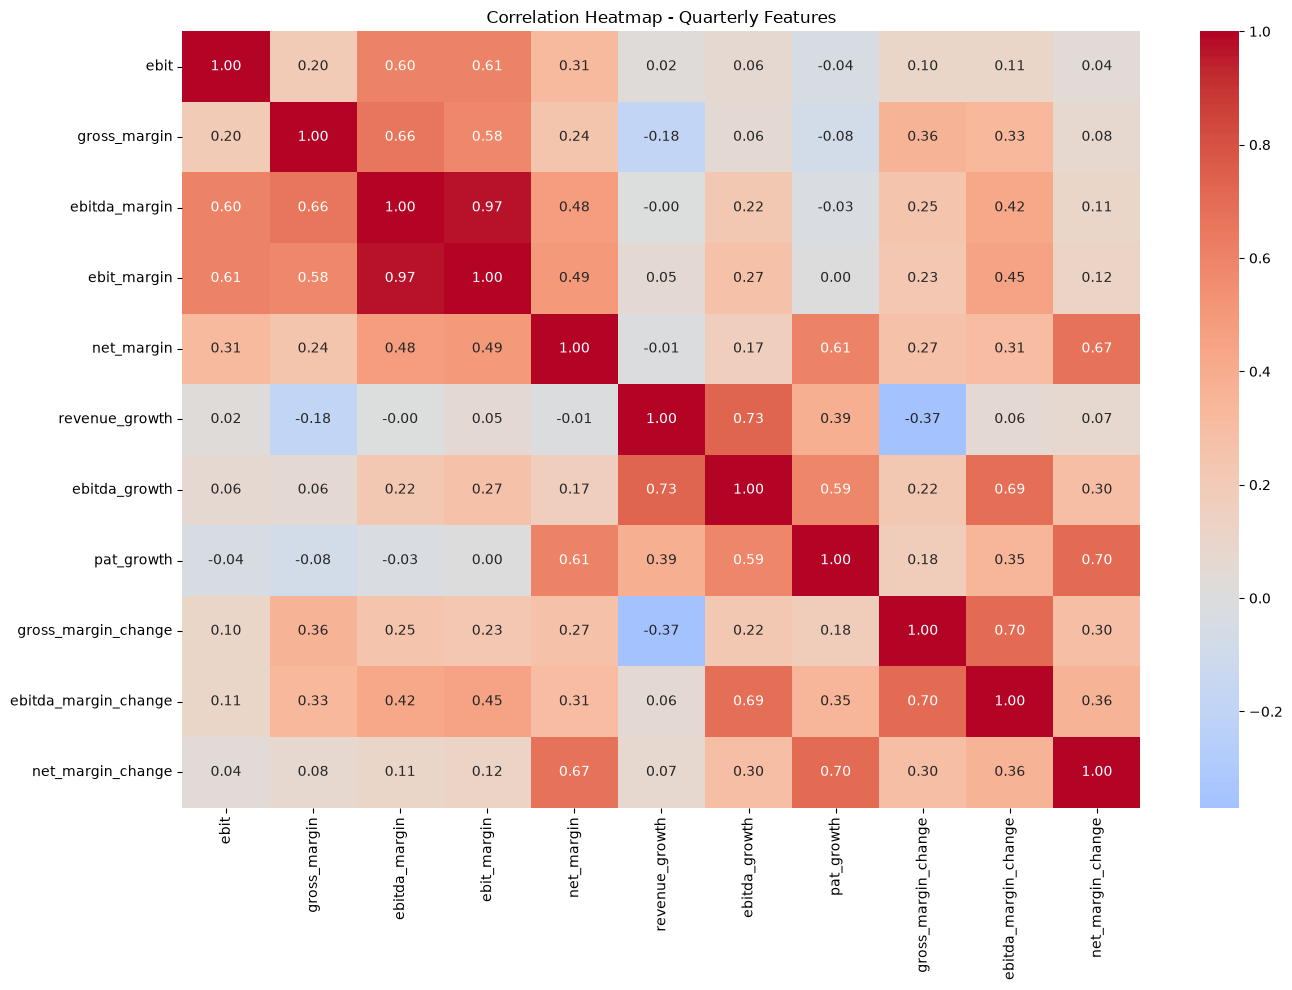

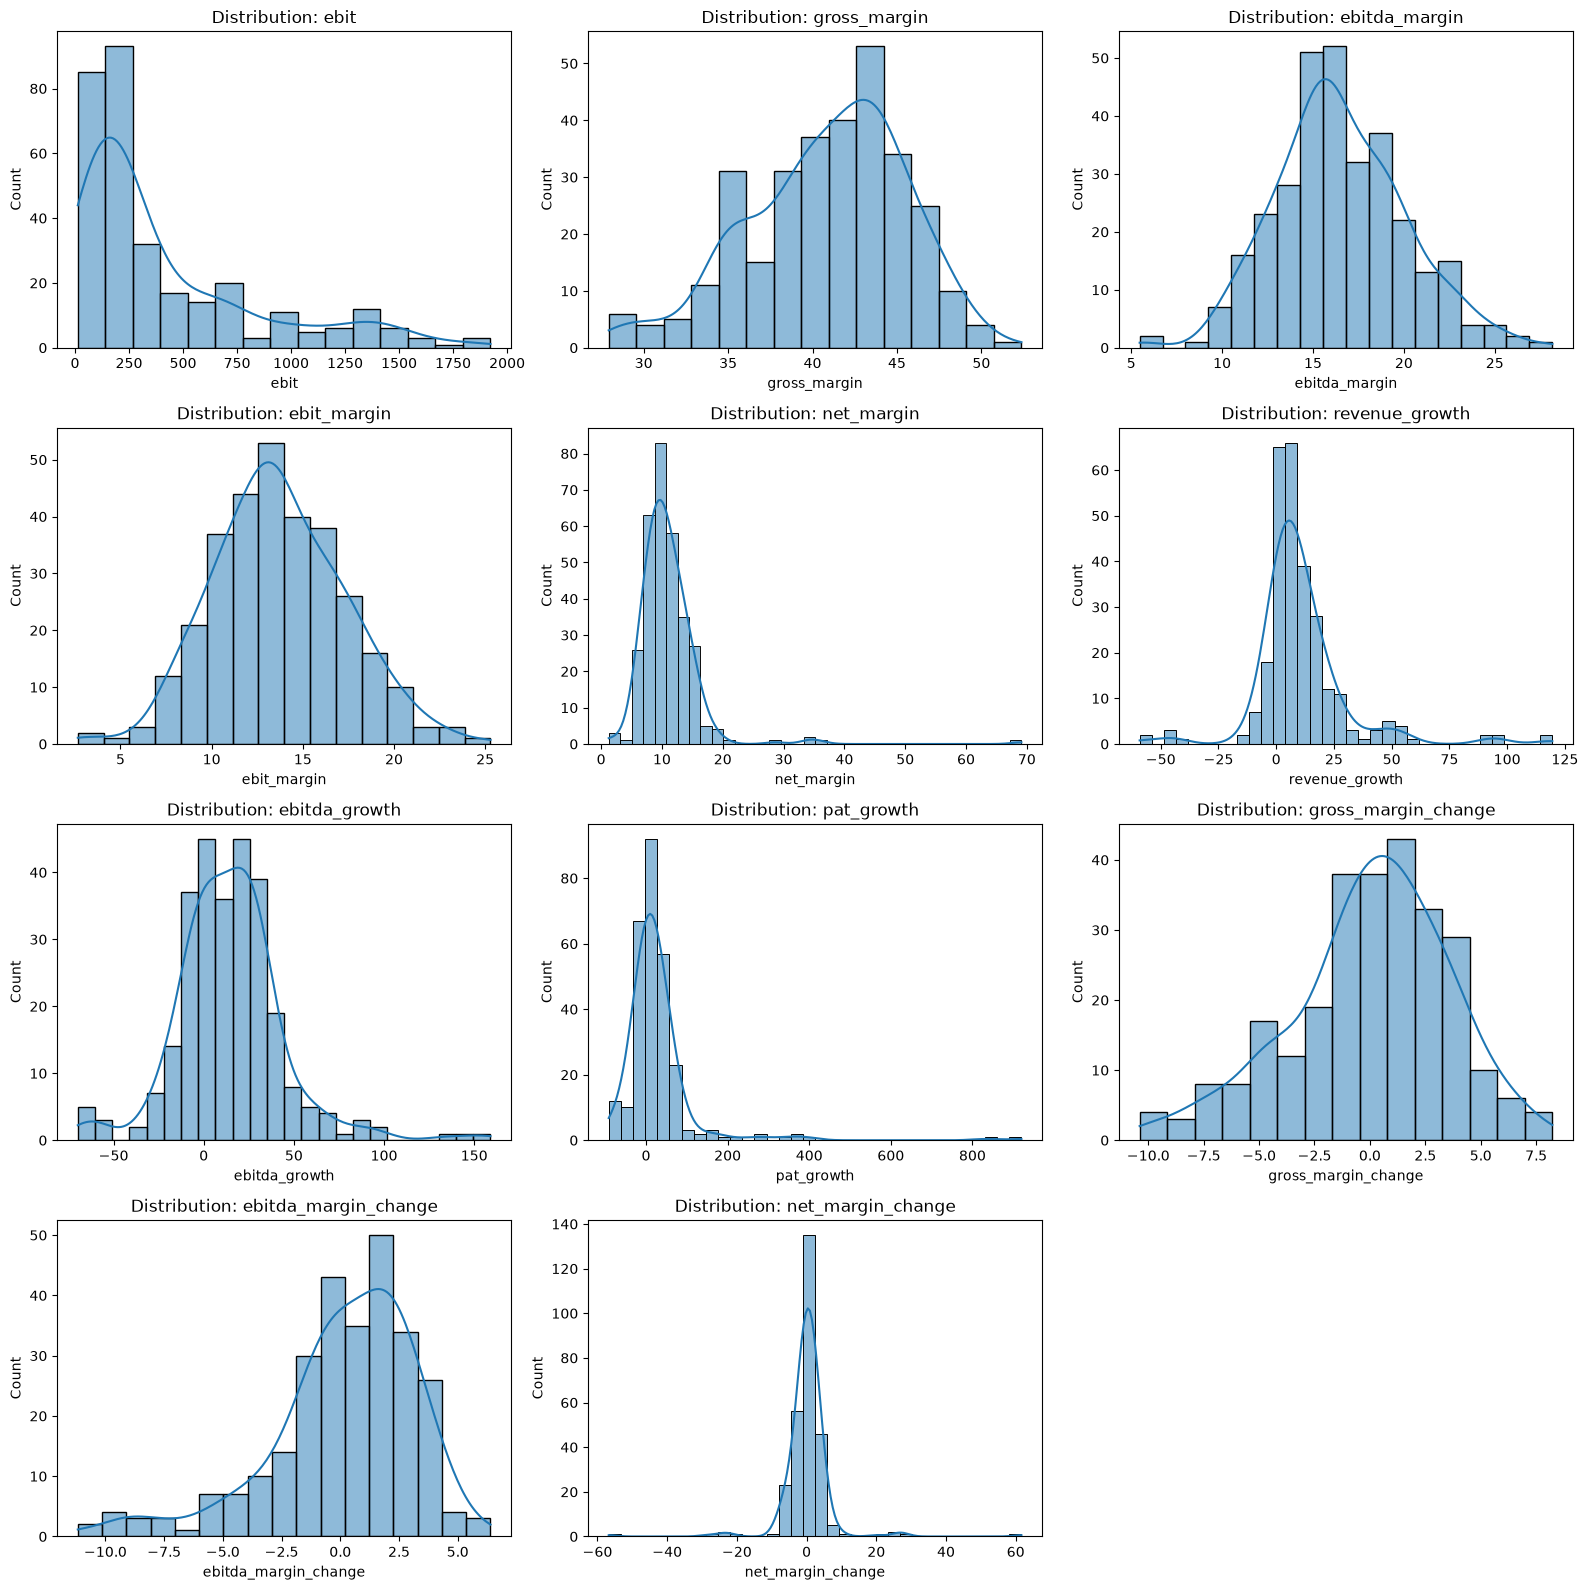

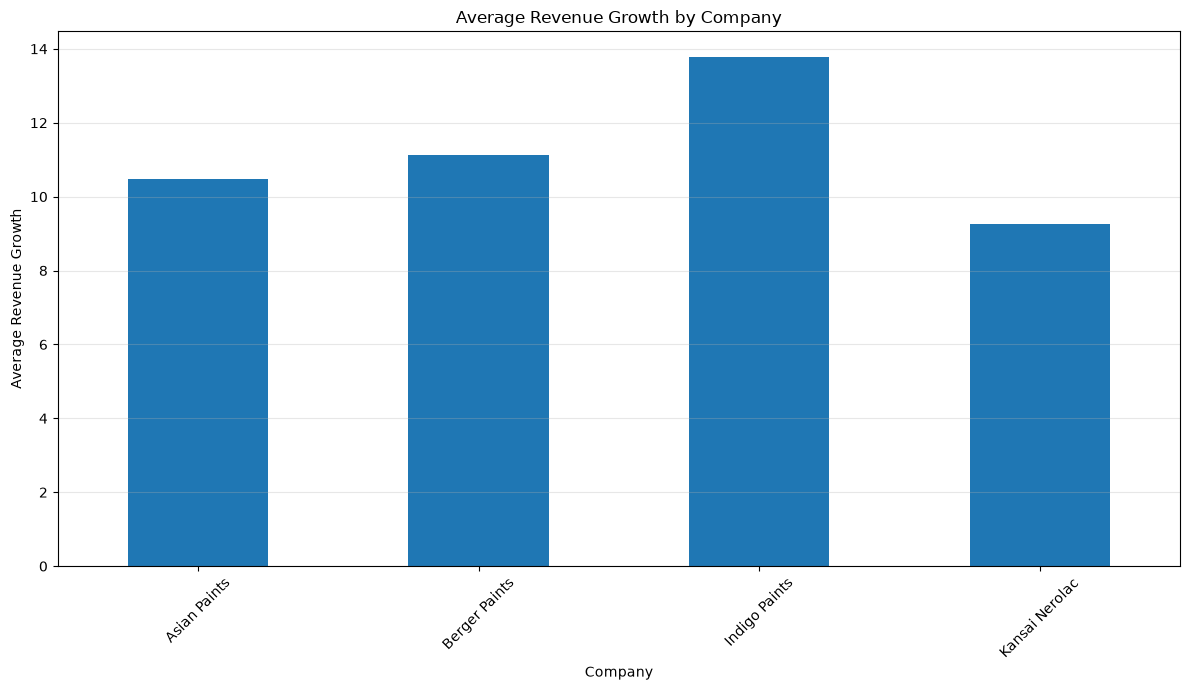

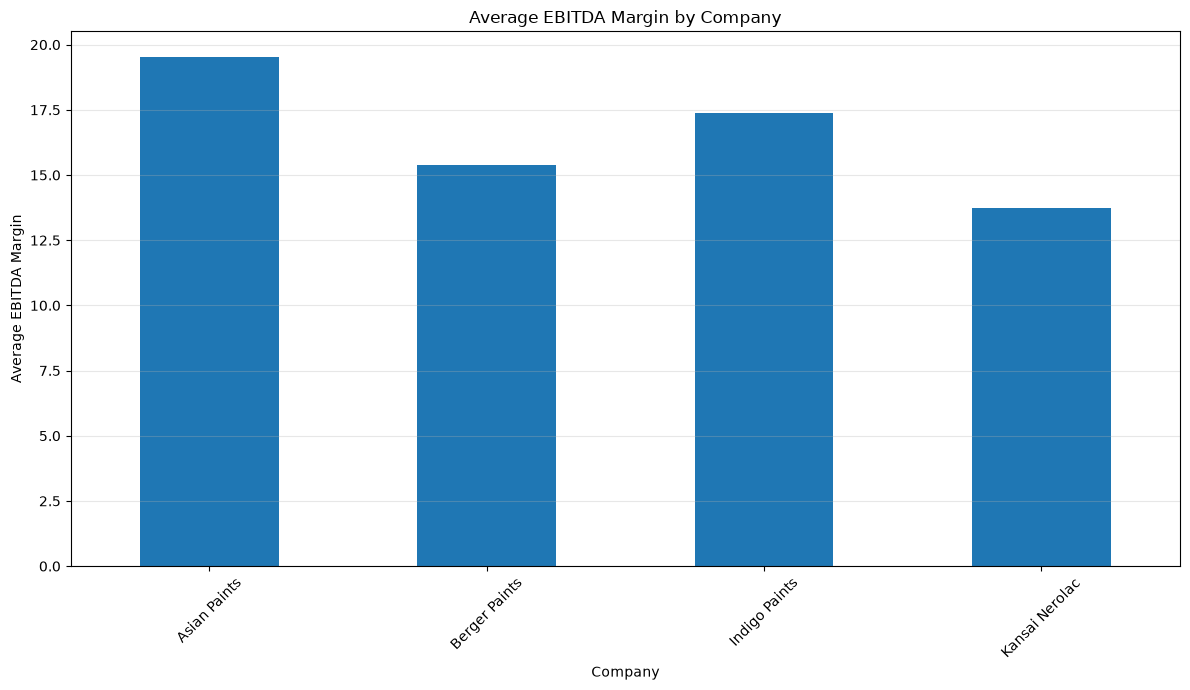

In [10]:
# ============================================
# QUARTERLY DATA VISUALIZATION
# ============================================

# 1. Revenue Growth over time

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=quarterly_features,
    x='period_end',
    y='revenue_growth',
    hue='company',
    marker='o'
)

plt.title('Quarterly Revenue Growth by Company')
plt.xlabel('Quarter')
plt.ylabel('Revenue Growth')
plt.xticks(rotation=45)
plt.legend(title='Company')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 2. EBITDA Margin over time

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=quarterly_features,
    x='period_end',
    y='ebitda_margin',
    hue='company',
    marker='o'
)

plt.title('Quarterly EBITDA Margin by Company')
plt.xlabel('Quarter')
plt.ylabel('EBITDA Margin')
plt.xticks(rotation=45)
plt.legend(title='Company')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 3. Revenue Growth Distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    data=quarterly_features,
    x='revenue_growth',
    kde=True
)

plt.title('Distribution of Revenue Growth')
plt.xlabel('Revenue Growth')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

# 4. EBITDA Margin Distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    data=quarterly_features,
    x='ebitda_margin',
    kde=True
)

plt.title('Distribution of EBITDA Margin')
plt.xlabel('EBITDA Margin')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

# 5. Revenue Growth by Company

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=quarterly_features,
    x='company',
    y='revenue_growth'
)

plt.title('Revenue Growth by Company')
plt.xlabel('Company')
plt.ylabel('Revenue Growth')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# 6. EBITDA Margin by Company

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=quarterly_features,
    x='company',
    y='ebitda_margin'
)

plt.title('EBITDA Margin by Company')
plt.xlabel('Company')
plt.ylabel('EBITDA Margin')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# 7. Correlation Heatmap

numeric_data = quarterly_features.select_dtypes(
    include=np.number
)

plt.figure(figsize=(14, 10))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Heatmap - Quarterly Features')

plt.tight_layout()
plt.show()

# 8. Distribution of Numerical Features

numeric_columns = quarterly_features.select_dtypes(
    include=np.number
).columns

n_cols = 3
n_rows = int(np.ceil(len(numeric_columns) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 4 * n_rows)
)

axes = np.array(axes).reshape(-1)

for i, column in enumerate(numeric_columns):
    sns.histplot(
        data=quarterly_features,
        x=column,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(
        f'Distribution: {column}'
    )

for i in range(
        len(numeric_columns),
        len(axes)
):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

# 9. Average Revenue Growth by Company

revenue_growth_mean = quarterly_features.groupby(
    'company'
)['revenue_growth'].mean()

plt.figure(figsize=(12, 7))

revenue_growth_mean.plot(
    kind='bar'
)

plt.title('Average Revenue Growth by Company')
plt.xlabel('Company')
plt.ylabel('Average Revenue Growth')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# 10. Average EBITDA Margin by Company

ebitda_margin_mean = quarterly_features.groupby(
    'company'
)['ebitda_margin'].mean()

plt.figure(figsize=(12, 7))

ebitda_margin_mean.plot(
    kind='bar'
)

plt.title('Average EBITDA Margin by Company')
plt.xlabel('Company')
plt.ylabel('Average EBITDA Margin')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()